# LoRA trainer: ontology extraction and documentation memory

Two LoRA adapters trained on the same documentation sections (`For_training = 1`, `is_TO_DO = 0`):

1. **Ontology**: `Qwen/Qwen2.5-0.5B-Instruct` learns to extract a section's entities and relationships as JSON (`entity_instruct`). Saved to `data/ontology_lora.bin`.
2. **Memory**: `Qwen/Qwen2.5-Coder-0.5B-Instruct` learns the raw documentation text (`text`). Saved to `data/memory_lora.bin`.

**Data:** one shared 80/10/10 split (sklearn, seed 6037784), named `training_set`, `test_set`, `dev_set`. For each token sequence `t`, `X = t[:-1]` and `Y = t[1:]`.

**Error:** mean per-token cross-entropy of predicting `Y`.

**Stopping:** training stops after 1000 optimizer steps, or as soon as the dev error drops below 0.005. The weights saved are the ones from the step with the **lowest dev error**.

> Import `rag_etl` before `torch`: it sets the environment variables torch needs on this machine.

In [1]:
from rag_etl import lora  # first: sets torch env vars before torch is imported
from rag_etl.ontology import build_entity_dataset
from rag_etl.plots import plot_history

import gc
import json

import numpy as np
import pandas as pd
import torch

pd.set_option("display.max_colwidth", 120)

SEED = lora.SEED                       # 6037784
SECTIONS_PATH = "data/sections.parquet"
ONTOLOGY_SOURCE = "data/ontology_source"
ONTOLOGY_PATH = "data/ontology.json"
DATASET_PATH = "data/dataset_entities.parquet"
ONTOLOGY_LORA_PATH = "data/ontology_lora.bin"
MEMORY_LORA_PATH = "data/memory_lora.bin"

TRAIN_KW = dict(
    max_steps=1000,          # stop after 1000 optimizer steps ...
    target_dev_loss=0.005,   # ... or when the dev error drops below 0.005
    grad_accum=4,            # sequences per optimizer step
    lr=2e-4,
    eval_every=25,           # dev error measured every 25 steps
    seed=SEED,
)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

NVIDIA GeForce RTX 3080 Ti


## 1. Ontology and entities dataset

Claude read every training section and wrote one annotation per section to `data/ontology_source/rows/*.jsonl` (entities with types, plus the relationships between them), plus a synonym list in `data/ontology_source/synonyms.json`.
This step validates those annotations and builds:
- `data/ontology.json`: entity types, merged relationships with provenance, and synonyms
- `data/dataset_entities.parquet`: the sections plus an `entities` JSON column

The same step runs from the command line with `build-ontology`.

In [2]:
df, ontology = build_entity_dataset(SECTIONS_PATH, ONTOLOGY_SOURCE, ONTOLOGY_PATH, DATASET_PATH)
print(json.dumps(ontology["stats"], indent=1))
pd.DataFrame(ontology["relationships"])[["source", "relation", "target", "projects", "count"]].sort_values("count", ascending=False).head(10)

{
 "sections": 248,
 "entities": 766,
 "entities_by_type": {
  "Alert": 5,
  "Component": 143,
  "Concept": 118,
  "Config": 57,
  "Datastore": 38,
  "Endpoint": 58,
  "Environment": 10,
  "Error": 37,
  "Field": 96,
  "Job": 6,
  "Person": 8,
  "Process": 37,
  "Queue": 5,
  "Service": 49,
  "Table": 11,
  "Team": 11,
  "Technology": 31,
  "Tool": 46
 },
 "relationships": 1063,
 "canonical_with_synonyms": 62,
 "aliases": 100
}


,source,relation,target,projects,count
369,PaymentPromiseService,calls,Promise Service,[payment-promise-gateway],7
361,PaymentPromiseController,calls,PaymentPromiseService,[payment-promise-gateway],7
720,catalog-portfolio-api,uses,Gradle,[catalog-portfolio-api],6
729,catalog-portfolio-api,uses,MySQL,[catalog-portfolio-api],6
692,catalog-portfolio-api,raises,brand_not_found,[catalog-portfolio-api],5
898,payment-promise-gateway,exposes,POST /payment_promise,[payment-promise-gateway],4
899,payment-promise-gateway,exposes,PUT /forgiveness_proposal,[payment-promise-gateway],4
896,payment-promise-gateway,exposes,GET /payment_promise/form,[payment-promise-gateway],4
718,catalog-portfolio-api,uses,Connection pooling,[catalog-portfolio-api],4
895,payment-promise-gateway,exposes,GET /payment_promise/active,[payment-promise-gateway],4


In [3]:
# Synonyms (canonical -> aliases), a sample
pd.DataFrame([{"canonical": k, "type": v["type"], "aliases": v["aliases"]} for k, v in ontology["synonyms"].items()]).head(10)

,canonical,type,aliases
0,1p-materials,Service,[materials]
1,AWS WAF,Service,"[WAF, Web Application Firewall]"
2,Automatic version,Process,"[automatic versions, version creation]"
3,Backport,Process,[backports]
4,BigQ,Technology,"[Big-Queue, MegaQueue, RetailHub-BigQ]"
5,BigSeller,Concept,[Big Seller]
6,Blocked IP,Concept,[IP bloqueada]
7,Bottom Up,Concept,[bu]
8,Branch protection,Concept,[protected branches]
9,Brand,Concept,[merchant]


## 2. `entity_instruct`: the training text for the ontology task

In [4]:
df = lora.add_entity_instruct(df)
print(df["entity_instruct"].iloc[3])

{"instruction": "Extract the entities and relationships from the following document in the specified JSON format.", "input": "file_name: README.md \n project: 2p-revenue-optimizer-api \n version: latest \n section: Spring Boot App model for Java 17 > Usage > Main \n text: The main class for this app is Application, where Spring context is initialized and SCOPE_SUFFIX is generated.", "output": {"entities": [{"name": "Application", "type": "Component"}, {"name": "Spring context", "type": "Component"}, {"name": "SCOPE_SUFFIX", "type": "Config"}], "relationships": [{"source": "Application", "relation": "initializes", "target": "Spring context"}, {"source": "Application", "relation": "generates", "target": "SCOPE_SUFFIX"}]}}


## 3. Tokenize with the Qwen2.5 BPE tokenizer
Both models use the same tokenizer (checked below). An end-of-text token is appended to each sequence so the model learns where an extraction or a document ends.

In [5]:
tokenizer = lora.load_tokenizer(lora.ONTOLOGY_MODEL)
coder_tokenizer = lora.load_tokenizer(lora.MEMORY_MODEL)
assert tokenizer.get_vocab() == coder_tokenizer.get_vocab(), "tokenizers differ"

df = lora.add_token_columns(df, tokenizer)
pd.DataFrame({
    "entity_instruct_tok": df["entity_instruct_tok"].map(len).describe(),
    "text_tok": df["text_tok"].map(len).describe(),
}).round(0)

,entity_instruct_tok,text_tok
count,248.0,248.0
mean,463.0,175.0
std,598.0,372.0
min,84.0,4.0
25%,184.0,37.0
50%,278.0,64.0
75%,527.0,164.0
max,5129.0,2966.0


## 4. Split 80 / 10 / 10 and build X / Y

In [6]:
training_set, test_set, dev_set = lora.split_dataset(df, seed=SEED)
print(f"training_set {len(training_set)} | test_set {len(test_set)} | dev_set {len(dev_set)}")

X_train_ontology, Y_train_ontology = lora.make_xy(training_set["entity_instruct_tok"])
X_test_ontology, Y_test_ontology = lora.make_xy(test_set["entity_instruct_tok"])
X_dev_ontology, Y_dev_ontology = lora.make_xy(dev_set["entity_instruct_tok"])

X_train_memory, Y_train_memory = lora.make_xy(training_set["text_tok"])
X_test_memory, Y_test_memory = lora.make_xy(test_set["text_tok"])
X_dev_memory, Y_dev_memory = lora.make_xy(dev_set["text_tok"])

# Y is X shifted by one token
assert all((x[1:] == y[:-1]).all() for x, y in zip(X_train_ontology, Y_train_ontology))
assert all((x[1:] == y[:-1]).all() for x, y in zip(X_train_memory, Y_train_memory))
pd.DataFrame(
    {
        "ontology tokens": [sum(map(len, Y)) for Y in (Y_train_ontology, Y_dev_ontology, Y_test_ontology)],
        "memory tokens": [sum(map(len, Y)) for Y in (Y_train_memory, Y_dev_memory, Y_test_memory)],
    },
    index=["train", "dev", "test"],
)

training_set 198 | test_set 25 | dev_set 25


,ontology tokens,memory tokens
train,96031,36952
dev,9273,2820
test,9361,3411


## 5. Ontology adapter: `Qwen2.5-0.5B-Instruct`
LoRA settings: r=16, alpha=32, dropout 0.05, on all attention and MLP projections (~8.8M trainable parameters). Each optimizer step uses 4 full sequences, with no truncation.

In [7]:
model = lora.load_lora_model(lora.ONTOLOGY_MODEL)
model.print_trainable_parameters()
ontology_base_test = lora.evaluate(model, X_test_ontology, Y_test_ontology)

ontology_result = lora.train_lora(
    model, X_train_ontology, Y_train_ontology, X_dev_ontology, Y_dev_ontology,
    save_path=ONTOLOGY_LORA_PATH, **TRAIN_KW,
)
print(f"stopped by {ontology_result.stop_reason} after {ontology_result.steps_run} steps "
      f"in {ontology_result.seconds / 60:.1f} min; saved best-dev weights (step {ontology_result.best_step}) to {ONTOLOGY_LORA_PATH}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
step    0 | train 1.3730 | dev 1.6110
step   25 | train 1.0573 | dev 0.9424 | best dev 0.9424 @ 25
step   50 | train 0.8799 | dev 0.8217 | best dev 0.8217 @ 50
step   75 | train 0.7099 | dev 0.7776 | best dev 0.7776 @ 75
step  100 | train 0.5700 | dev 0.7485 | best dev 0.7485 @ 100
step  125 | train 0.4773 | dev 0.7571 | best dev 0.7485 @ 100
step  150 | train 0.5086 | dev 0.7453 | best dev 0.7453 @ 150
step  175 | train 0.3627 | dev 0.7678 | best dev 0.7453 @ 150
step  200 | train 0.3751 | dev 0.7763 | best dev 0.7453 @ 150
step  225 | train 0.2210 | dev 0.8252 | best dev 0.7453 @ 150
step  250 | train 0.2930 | dev 0.8409 | best dev 0.7453 @ 150
step  275 | train 0.2078 | dev 0.8540 | best dev 0.7453 @ 150
step  300 | train 0.1963 | dev 0.9013 | best dev 0.7453 @ 150
step  325 | train 0.1491 | dev 0.8921 | best dev 0.7453 @ 150
step  350 | train 0.1581 | dev 0.9335 | best dev 0.7453 @ 150
step  375 | train 0.

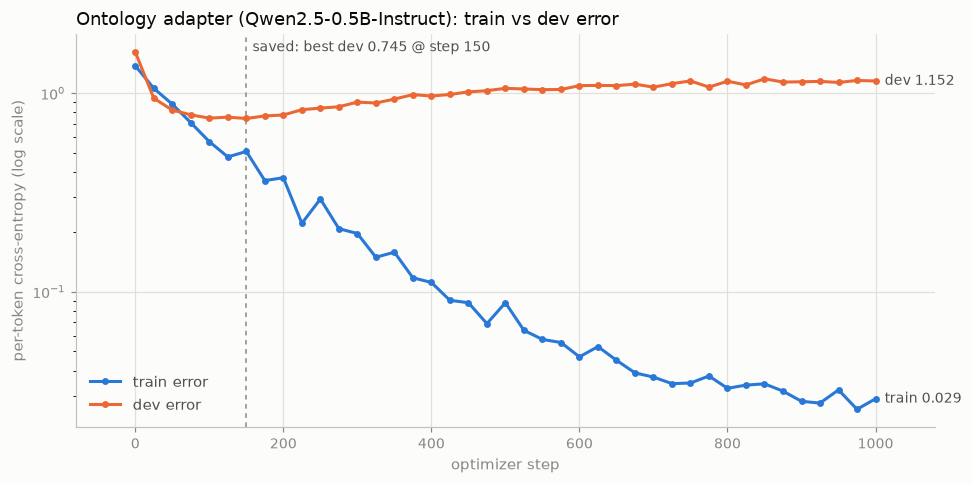

In [8]:
plot_history(ontology_result, "Ontology adapter (Qwen2.5-0.5B-Instruct): train vs dev error");

In [9]:
ontology_test = lora.evaluate(model, X_test_ontology, Y_test_ontology)
print(f"Test error (per-token cross-entropy): base model {ontology_base_test:.4f} -> LoRA {ontology_test:.4f} "
      f"(perplexity {np.exp(ontology_base_test):.2f} -> {np.exp(ontology_test):.2f})")
ontology_result.history.round(4).tail(8)

Test error (per-token cross-entropy): base model 1.6331 -> LoRA 0.7875 (perplexity 5.12 -> 2.20)


,step,train_loss,dev_loss
33,825,0.0338,1.1002
34,850,0.0344,1.1809
35,875,0.0316,1.1373
36,900,0.0281,1.1409
37,925,0.0275,1.1461
38,950,0.0320,1.1320
39,975,0.0256,1.1587
40,1000,0.0289,1.1515


In [10]:
# What the adapter extracts for a test section it never saw
row = test_set.iloc[0]
generated = lora.generate(model, tokenizer, lora.instruct_prompt(row), max_new_tokens=400)
print("SECTION:", row["path"], "#", row["section"])
print("\nGENERATED:\n", generated[:1500])
print("\nGOLD:\n", json.dumps(json.loads(row["entities"]), ensure_ascii=False)[:1500])

SECTION: catalog-portfolio-api/latest/guide/troubleshooting/README.md # Troubleshooting > Common Error Categories > 🔧 Startup Issues

GENERATED:
  {"entities": [{"name": "catalog-portfolio-api", "type": "Service"}, {"name": "Port already in use", "type": "Error"}, {"name": "Database connection failed", "type": "Error"}, {"name": "MySQL", "type": "Technology"}, {"name": "Connection refused", "type": "Error"}, {"name": "FileNotFoundException", "type": "Error"}, {"name": "Database schema validation", "type": "Process"}], "relationships": [{"source": "catalog-portfolio-api", "relation": "raises", "target": "Port already in use"}, {"source": "catalog-portfolio-api", "relation": "raises", "target": "Database connection failed"}, {"source": "catalog-portfolio-api", "relation": "raises", "target": "MySQL"}, {"source": "catalog-portfolio-api", "relation": "raises", "target": "Connection refused"}, {"source": "catalog-portfolio-api", "relation": "raises", "target": "FileNotFoundException"}, {"so

In [11]:
del model
gc.collect()
torch.cuda.empty_cache()

## 6. Memory adapter: `Qwen2.5-Coder-0.5B-Instruct`
Same split, LoRA settings and stopping rule as section 5. The target is now the raw section text (`X_*_memory`).

In [12]:
model = lora.load_lora_model(lora.MEMORY_MODEL)
memory_base_test = lora.evaluate(model, X_test_memory, Y_test_memory)

memory_result = lora.train_lora(
    model, X_train_memory, Y_train_memory, X_dev_memory, Y_dev_memory,
    save_path=MEMORY_LORA_PATH, **TRAIN_KW,
)
print(f"stopped by {memory_result.stop_reason} after {memory_result.steps_run} steps "
      f"in {memory_result.seconds / 60:.1f} min; saved best-dev weights (step {memory_result.best_step}) to {MEMORY_LORA_PATH}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

step    0 | train 1.8725 | dev 2.5666
step   25 | train 1.7390 | dev 2.1881 | best dev 2.1881 @ 25
step   50 | train 1.6604 | dev 1.9893 | best dev 1.9893 @ 50
step   75 | train 1.3719 | dev 1.9168 | best dev 1.9168 @ 75
step  100 | train 1.1403 | dev 1.8671 | best dev 1.8671 @ 100
step  125 | train 0.8698 | dev 1.9157 | best dev 1.8671 @ 100
step  150 | train 1.0429 | dev 1.9187 | best dev 1.8671 @ 100
step  175 | train 0.6762 | dev 2.0248 | best dev 1.8671 @ 100
step  200 | train 0.6564 | dev 2.0847 | best dev 1.8671 @ 100
step  225 | train 0.4460 | dev 2.2749 | best dev 1.8671 @ 100
step  250 | train 0.4305 | dev 2.3342 | best dev 1.8671 @ 100
step  275 | train 0.3888 | dev 2.4388 | best dev 1.8671 @ 100
step  300 | train 0.3260 | dev 2.4630 | best dev 1.8671 @ 100
step  325 | train 0.2585 | dev 2.5182 | best dev 1.8671 @ 100
step  350 | train 0.2568 | dev 2.5283 | best dev 1.8671 @ 100
step  375 | train 0.2024 | dev 2.6121 | best dev 1.8671 @ 100
step  400 | train 0.1903 | dev 2.74

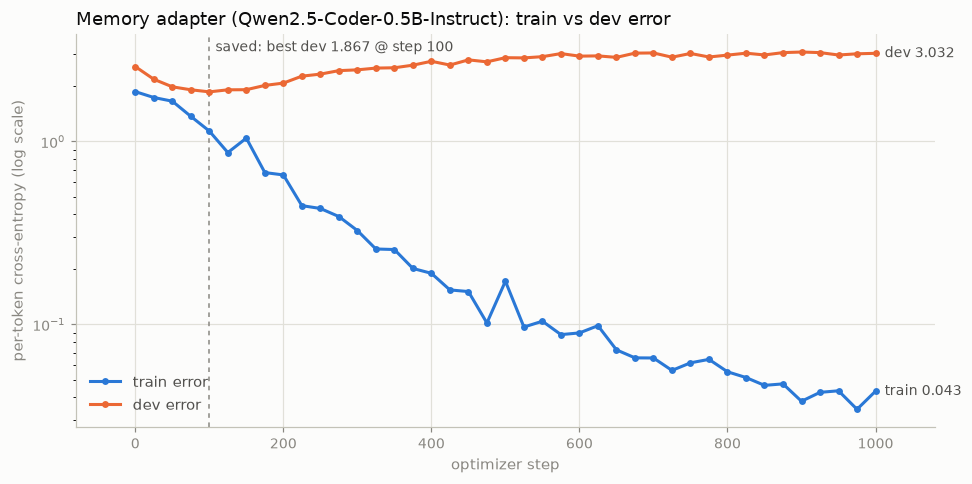

In [13]:
plot_history(memory_result, "Memory adapter (Qwen2.5-Coder-0.5B-Instruct): train vs dev error");

In [14]:
memory_test = lora.evaluate(model, X_test_memory, Y_test_memory)
print(f"Test error (per-token cross-entropy): base model {memory_base_test:.4f} -> LoRA {memory_test:.4f} "
      f"(perplexity {np.exp(memory_base_test):.2f} -> {np.exp(memory_test):.2f})")
memory_result.history.round(4).tail(8)

Test error (per-token cross-entropy): base model 2.2692 -> LoRA 1.7281 (perplexity 9.67 -> 5.63)


,step,train_loss,dev_loss
33,825,0.0513,3.0378
34,850,0.0465,2.9708
35,875,0.0473,3.0597
36,900,0.0380,3.0822
37,925,0.0426,3.0600
38,950,0.0434,2.9692
39,975,0.0344,3.0141
40,1000,0.0432,3.0325


## 7. Summary

In [15]:
pd.DataFrame(
    {
        "ontology (Qwen2.5-0.5B-Instruct)": {
            "steps run": ontology_result.steps_run, "stop reason": ontology_result.stop_reason,
            "saved step (best dev)": ontology_result.best_step, "best dev error": round(ontology_result.best_dev_loss, 4),
            "test error, base": round(ontology_base_test, 4), "test error, LoRA": round(ontology_test, 4),
            "minutes": round(ontology_result.seconds / 60, 1), "weights": ONTOLOGY_LORA_PATH,
        },
        "memory (Qwen2.5-Coder-0.5B-Instruct)": {
            "steps run": memory_result.steps_run, "stop reason": memory_result.stop_reason,
            "saved step (best dev)": memory_result.best_step, "best dev error": round(memory_result.best_dev_loss, 4),
            "test error, base": round(memory_base_test, 4), "test error, LoRA": round(memory_test, 4),
            "minutes": round(memory_result.seconds / 60, 1), "weights": MEMORY_LORA_PATH,
        },
    }
)

,ontology (Qwen2.5-0.5B-Instruct),memory (Qwen2.5-Coder-0.5B-Instruct)
steps run,1000,1000
stop reason,max_steps,max_steps
saved step (best dev),150,100
best dev error,0.7453,1.8671
"test error, base",1.6331,2.2692
"test error, LoRA",0.7875,1.7281
minutes,7.8,6.2
weights,data/ontology_lora.bin,data/memory_lora.bin


### Takeaways (RTX 3080 Ti, about 14 minutes for both runs)

- **Ontology adapter:** the test error fell from 1.633 to 0.788 (perplexity 5.12 to 2.20). The best dev error, 0.745, came at step 150. After that the train error keeps dropping (to about 0.03) while the dev error climbs back to about 1.15: with 198 training sections the adapter starts memorizing them. In the sample extraction, the format is right and most entities are correct, but it adds one wrong relationship (`raises MySQL`) and turns symptom strings into errors.
- **Memory adapter:** the test error fell from 2.269 to 1.728 (perplexity 9.67 to 5.63). The best dev error, 1.867, came at step 100. The dev error then rises to about 3.0 while the train error reaches about 0.04: the adapter memorizes the sections it saw, and that knowledge doesn't carry over to held-out sections, which contain facts it never trained on. That is expected for a memory task. It also means held-out documents need retrieval.
- **The 0.005 dev target is never reached.** Both runs stop at 1,000 steps, and saving the best-dev checkpoint, not the last one, is what keeps the useful adapter. Stopping after 4 evaluations without improvement would save about 85% of the compute with the same saved weights.
- **Next:** compute the extraction loss only on the `output` tokens, and score extractions with entity-level precision and recall rather than token loss.